In [17]:
# 1. IMPORT LIBRARIES & LOAD DATA
# ------------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, 
    f1_score, classification_report, roc_auc_score
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

import tensorflow as tf
from tensorflow import keras

# Load Dataset
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [18]:

# 2. DATA CLEANING & PREPROCESSING
# ----------------------------------

# Step: 1 Checking missing values
print("Missing Values: ", df.isnull().sum())

# Step: 2 Checking data types of all columns
print("DataType: ", df.dtypes)

# MonthlyCharge is float but TotalCharge is object
# Step: 3 Checking unique values in TotalCharge so that can find text inside
print("Unique Values:",df['TotalCharges'].unique())

# Hidden Blank Spaces Found
# Step: 4 Counting hidden blank spaces
print("Hidden Blank Spaces: ")
print((df == " ").sum()[(df == " ").sum() > 0])

# Blank spaces Found : 11 
# Step: 5 Replacing blank spaces with NaN and converting datatype to float
df["TotalCharges"] = df["TotalCharges"].replace(" ", np.nan)
df["TotalCharges"] = df["TotalCharges"].astype(float)

# Step: 6 Re-checking missing values to confirm NaN conversion
print("Missing Values After Conversion: ", df.isnull().sum())

# Step: 7 Droping rows with missing values and unnecessary columns
df.dropna(inplace=True)
df.drop("customerID", axis=1, inplace=True)

print("Cleaned Data Shape: ", df.shape)

# Step: 8 Categorical and Numerical columns
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns
categorical_cols = df.select_dtypes(include=['object']).columns
print("Numerical Columns:", numerical_cols.tolist())
print("Categorical Columns:", categorical_cols.tolist())

Missing Values:  customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64
DataType:  customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod        

C:\Users\hp\AppData\Local\Temp\ipykernel_5312\3886972112.py:35: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=['object']).columns


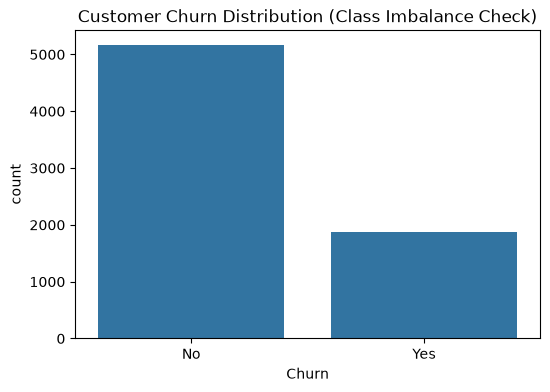

Churn
No     73.421502
Yes    26.578498
Name: proportion, dtype: float64


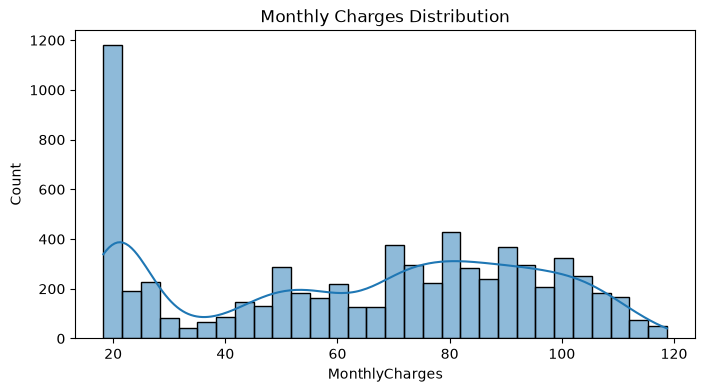

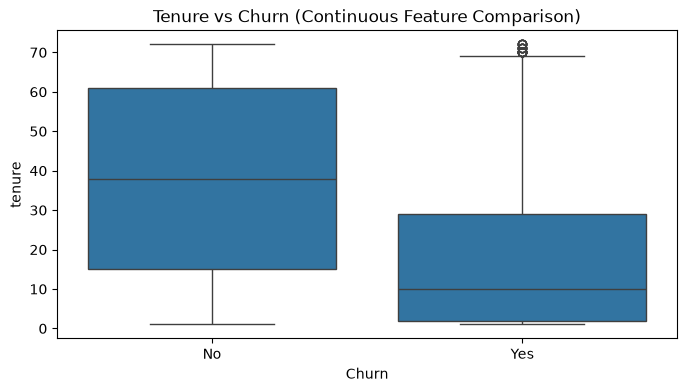

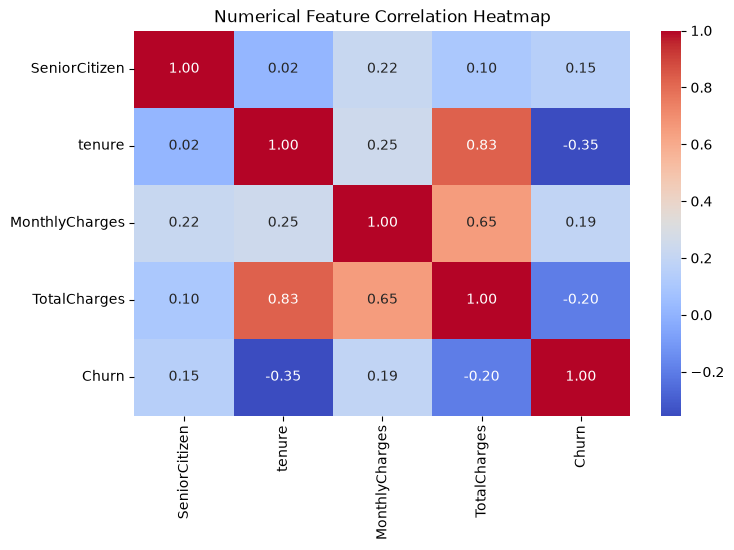

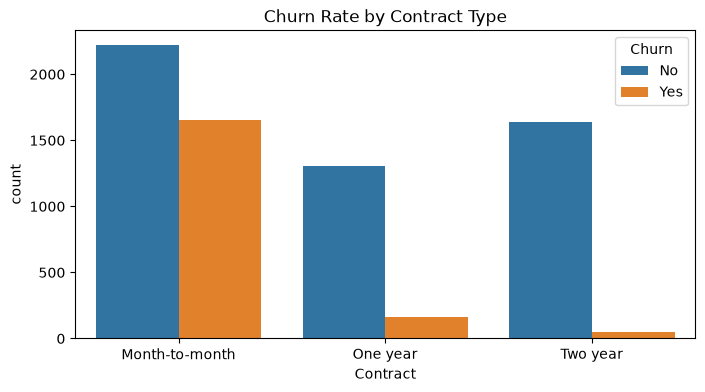

Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.72  11.28
Two year        97.15   2.85


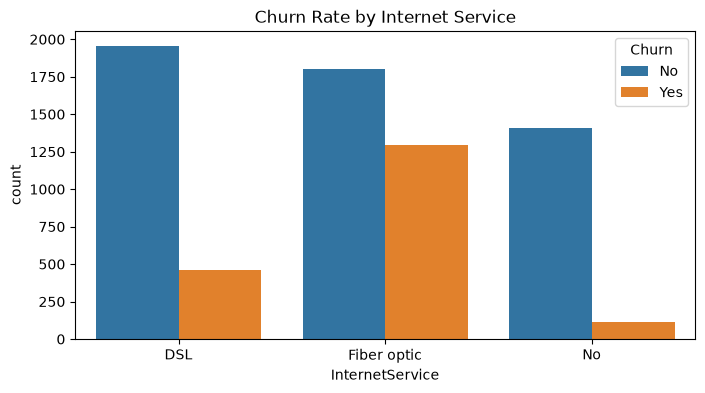

Churn               No    Yes
InternetService              
DSL              81.00  19.00
Fiber optic      58.11  41.89
No               92.57   7.43


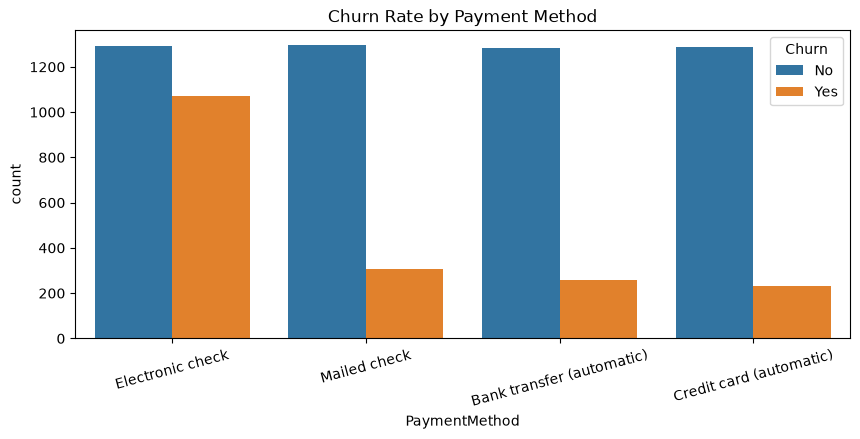

Churn                         No    Yes
PaymentMethod                          
Bank transfer (automatic)  83.27  16.73
Credit card (automatic)    84.75  15.25
Electronic check           54.71  45.29
Mailed check               80.80  19.20


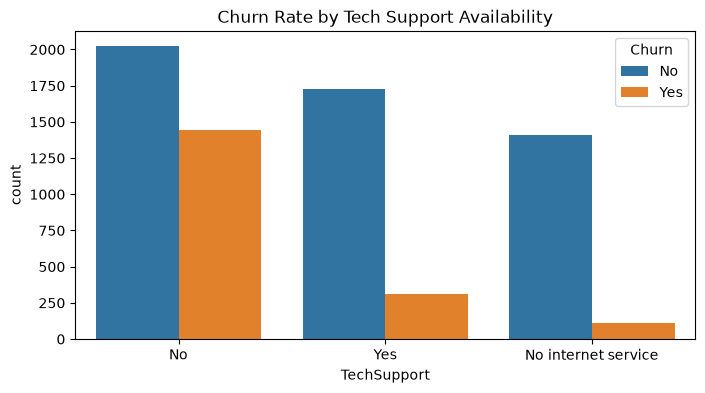

Churn                   No    Yes
TechSupport                      
No                   58.35  41.65
No internet service  92.57   7.43
Yes                  84.80  15.20


In [24]:
# 3. EXPLORATORY DATA ANALYSIS (EDA)
# ------------------------------------------

# A. Target Variable & Distribution Analysis
# ------------------------------------------

# Figure 1. Checking target variable is balanced or imbalanced
plt.figure(figsize=(6, 4))
sns.countplot(x='Churn', data=df)
plt.title("Customer Churn Distribution (Class Imbalance Check)")
plt.show()
print(df["Churn"].value_counts(normalize=True) * 100)
# Result: Imbalanced data (approximately 73% No Churn vs 27% Churn)

# Figure 2. Finding monthly charges distribution
plt.figure(figsize=(8, 4))
sns.histplot(df['MonthlyCharges'], bins=30, kde=True)
plt.title("Monthly Charges Distribution")
plt.show()
# Result: Bimodal distribution; a huge peak exists at lower monthly charges ($20 range) with liitle bit increase around $70 - $90

# Figure 3. Tenure Distributions
plt.figure(figsize=(8, 4))
sns.boxplot(x='Churn', y='tenure', data=df)
plt.title("Tenure vs Churn (Continuous Feature Comparison)")
plt.show()
# Result: Churned customers have a significantly lower median tenure, showing that customer cancellation risk is highest during early months.

# B. Numerical Correlation Analysis
# ------------------------------------------

# Figure 4. Correlation Heatmap for numerical features to measure correlation strength between numerical values and target variable
df_heatmap = df.copy()
df_heatmap["Churn"] = df_heatmap["Churn"].map({"No": 0, "Yes": 1})

plt.figure(figsize=(8, 5))
sns.heatmap(df_heatmap.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Numerical Feature Correlation Heatmap")
plt.show()
# Result: Tenure has a strong negative correlation (-0.35) with churn, indicating that long-term customers are much less likely to leave.

# C. Categorical Feature Comparisons with target variable
# ------------------------------------------

# Figure 5. Churn by Contract Type
plt.figure(figsize=(8, 4))
sns.countplot(x='Contract', hue='Churn', data=df)
plt.title("Churn Rate by Contract Type")
plt.show()
print(pd.crosstab(df['Contract'], df['Churn'], normalize='index').round(4) * 100)
# Result: Customers on month-to-month contracts exhibit the highest churn rate (42.7%), whereas two-year contract holders rarely churn (2.8%).

# Figure 6. Churn by Internet Service (Fiber Optic vs DSL)
plt.figure(figsize=(8, 4))
sns.countplot(x='InternetService', hue='Churn', data=df)
plt.title("Churn Rate by Internet Service")
plt.show()
print(pd.crosstab(df['InternetService'], df['Churn'], normalize='index').round(4) * 100)
# Result: Fiber optic subscribers experience a noticeably higher churn rate (41.9%) compared to DSL users (19.0%).

# Figure 7. Churn by Payment Method (Electronic Check Risk)
plt.figure(figsize=(10, 4))
sns.countplot(x='PaymentMethod', hue='Churn', data=df)
plt.xticks(rotation=15)
plt.title("Churn Rate by Payment Method")
plt.show()
print(pd.crosstab(df['PaymentMethod'], df['Churn'], normalize='index').round(4) * 100)
# Result: Customers paying via electronic check have the highest churn rate across all payment methods (45.3%).

# Figure 8. Churn by Tech Support Availability
plt.figure(figsize=(8, 4))
sns.countplot(x='TechSupport', hue='Churn', data=df)
plt.title("Churn Rate by Tech Support Availability")
plt.show()
print(pd.crosstab(df['TechSupport'], df['Churn'], normalize='index').round(4) * 100)
# Result: Customers without technical support churn at a much higher rate (41.6%) than those enrolled in tech support (15.2%).

In [ ]:
# 4. FEATURE ENGINEERING & SPLITTING
# --------------------------------------

X = df.drop("Churn", axis=1)
y = df["Churn"]

# One-Hot Encoding 
X = pd.get_dummies(X, drop_first=True)

# Encode Target Variable
le = LabelEncoder()
y = le.fit_transform(y)

# Train-Test Split (Unscaled)
X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

# Standard Scaling (For Logistic Regression and Neural Networks ONLY) These are Distance & Optimization-Based Models
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Initialize list to collect model performance metrics
model_results = []

In [26]:
# 5. BASELINE MODELS (TREES vs SCALED LOGISTIC)
# ----------------------------------------------

# Logistic Regression (we use scaled data for this model)
lr = LogisticRegression(random_state=42, max_iter=1000)
lr.fit(X_train_scaled, y_train)
y_pred = lr.predict(X_test_scaled)
y_proba = lr.predict_proba(X_test_scaled)[:, 1]

model_results.append({
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1 Score": f1_score(y_test, y_pred),
    "ROC-AUC": roc_auc_score(y_test, y_proba)
})

# Decision Tree (we use unscaled data for this model)
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)
y_pred = dt.predict(X_test)
y_proba = dt.predict_proba(X_test)[:, 1]

model_results.append({
    "Model": "Decision Tree (Baseline)",
    "Accuracy": accuracy_score(y_test, y_pred ),
    "Precision": precision_score(y_test, y_pred ),
    "Recall": recall_score(y_test, y_pred ),
    "F1 Score": f1_score(y_test, y_pred ),
    "ROC-AUC": roc_auc_score(y_test, y_proba)
})

# Random Forest (we use unscaled data for this model)
rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)
y_proba = rf.predict_proba(X_test)[:, 1]

model_results.append({
    "Model": "Random Forest (Baseline)",
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1 Score": f1_score(y_test, y_pred),
    "ROC-AUC": roc_auc_score(y_test, y_proba)
})

# XGBoost (we use unscaled data for this model)
xgb = XGBClassifier(random_state=42, eval_metric="logloss")
xgb.fit(X_train, y_train)
y_pred = xgb.predict(X_test)
y_proba = xgb.predict_proba(X_test)[:, 1]

model_results.append({
    "Model": "XGBoost (Baseline)",
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1 Score": f1_score(y_test, y_pred),
    "ROC-AUC": roc_auc_score(y_test, y_proba)
})

In [27]:
# 6. HYPERPARAMETER TUNING
# -------------------------------

# Tuning Random Forest
parameters_grid_rf = {
    "n_estimators": [100, 200],
    "max_depth": [5, 10],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

grid_rf = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=parameters_grid_rf,
    cv=5,
    scoring="f1",
    n_jobs=-1
)
grid_rf.fit(X_train, y_train)
best_rf = grid_rf.best_estimator_
print(f"Best parameters : {best_rf}")

y_pred = best_rf.predict(X_test)
y_proba = best_rf.predict_proba(X_test)[:, 1]

model_results.append({
    "Model": "Random Forest (Tuned)",
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1 Score": f1_score(y_test, y_pred),
    "ROC-AUC": roc_auc_score(y_test, y_proba)
})

# Tuneing XGBoost
parameters_dist_xgb = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.01, 0.05, 0.1],
    "subsample": [0.8, 1.0]
}

random_search_xgb = RandomizedSearchCV(
    estimator=XGBClassifier(random_state=42, eval_metric="logloss"),
    param_distributions=parameters_dist_xgb,
    n_iter=15,
    cv=5,
    scoring="f1",
    random_state=42,
    n_jobs=-1
)
random_search_xgb.fit(X_train, y_train)
best_xgb = random_search_xgb.best_estimator_
print(f"Best parameters : {best_xgb}")

y_pred = best_xgb.predict(X_test)
y_proba = best_xgb.predict_proba(X_test)[:, 1]

model_results.append({
    "Model": "XGBoost (Tuned)",
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1 Score": f1_score(y_test, y_pred),
    "ROC-AUC": roc_auc_score(y_test, y_proba)
})

Best parameters : RandomForestClassifier(max_depth=10, random_state=42)
Best parameters : XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=5, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=None,
              num_parallel_tree=None, ...)


In [28]:
# 7. NEURAL NETWORK (DEEP LEARNING)
# -------------------------------------

# We sue scaled data for this model
model = keras.Sequential([
    keras.layers.Dense(64, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(32, activation='relu'),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

Training = model.fit(
    X_train_scaled, y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)

probabilities = model.predict(X_test_scaled).ravel()
predictions = (probabilities > 0.5).astype(int)

model_results.append({
    "Model": "Neural Network (Keras)",
    "Accuracy": accuracy_score(y_test, predictions),
    "Precision": precision_score(y_test, predictions),
    "Recall": recall_score(y_test, predictions),
    "F1 Score": f1_score(y_test, predictions),
    "ROC-AUC": roc_auc_score(y_test, probabilities)
})

c:\Users\hp\anaconda3\envs\tf_env\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step


In [34]:
# 8. COMPARISON TABLE FOR ALL MODELS
# -----------------------------------------
comparison = pd.DataFrame(model_results)
comparison = comparison.sort_values(by="F1 Score", ascending=False).reset_index(drop=True)

print("                         FINAL MODEL PERFORMANCE COMPARISON")
print("-"*80)
display(comparison)

                         FINAL MODEL PERFORMANCE COMPARISON
--------------------------------------------------------------------------------


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.803838,0.647590,0.574866,0.609065,0.835673
1,Neural Network (Keras),0.790334,0.618619,0.550802,0.582744,0.826461
2,XGBoost (Tuned),0.789623,0.622642,0.529412,0.572254,0.831911
3,Random Forest (Baseline),0.786780,0.620915,0.508021,0.558824,0.818081
4,Random Forest (Tuned),0.788913,0.628763,0.502674,0.558692,0.834461
5,XGBoost (Baseline),0.771144,0.576023,0.526738,0.550279,0.811390
6,Decision Tree (Baseline),0.718550,0.470109,0.462567,0.466307,0.636638


In [ ]:
# 9. BUSINESS INSIGHTS & RECOMMENDATIONS
# ---------------------------------------------------------
"""
1. Contract Conversion Incentives

    - Highest churn indicates that month-to-month customers have a churn rate of 42.7%.
    - Strategy: Reduce exposure with a 10-15% price reduction for 1-year or 2-year contracts.

2. Fiber Optic Service Improvement:

    - Fiber optic customers have a churn rate of 41.9%, most likely due to service and pricing issues.
    - Strategy: Assess service reliability and offer a 6-month bundle of free tech support.

3. Payment Method Migration:

    - Electronic check customers have a 45.3% churn rate.
    - Strategy: Encourage auto-pay via bank transfer or credit card, and offer small billing credits.

4. Early Engagement Strategies:

    - The tenure boxplot shows that the 1-year customer churn rate is the highest.
    - Strategy: Create a series of automated onboarding emails and proactive check-in support for new customers.
"""